# Data Loading & Preprocessing

In [72]:

# ==========================================
# Data Loading & Preprocessing
# ==========================================

from pathlib import Path
import pandas as pd

# 1. Dataset Path
DATA_DIR = Path("../../data/raw/COLDataset")

# 2. Load Train and Validation Datasets
train_df = pd.read_csv(DATA_DIR / "train.csv", encoding="utf-8-sig")
validation_df = pd.read_csv(DATA_DIR / "validation.csv", encoding="utf-8-sig")

# 3. Data Preprocessing
for df in [train_df, validation_df]:
    df["TEXT"] = df["TEXT"].fillna("").astype(str).str.strip()
    df["label"] = df["label"].astype(int)

# 4. Split Features and Labels
X_train = train_df["TEXT"]
y_train = train_df["label"]

X_validation = validation_df["TEXT"]
y_validation = validation_df["label"]

# 5. Check Dataset
print("Train:", train_df.shape)
print("Validation:", validation_df.shape)

print("\nTrain Label Distribution:")
print(y_train.value_counts())

print("\nValidation Label Distribution:")
print(y_validation.value_counts())

display(train_df[["TEXT", "label"]].head())


Train: (25726, 5)
Validation: (6431, 5)

Train Label Distribution:
label
0    13003
1    12723
Name: count, dtype: int64

Validation Label Distribution:
label
0    3220
1    3211
Name: count, dtype: int64


,TEXT,label
0,也是，想想物流爆仓等半个月和打砸抢烧丧尸围城一般冒着被黑人胖大妈一屁股坐死的风险半夜2点去门...,1
1,说这些。四川人是不是只有喝西北风才健康啊。抛开剂量谈毒性都是垃圾,1
2,不同构成，有绿绿也有天主教，两样都很多的，有真正非洲黑也有南亚那种黑，不过也没有很多，至少不...,0
3,台湾人这么说,0
4,曾泽生肯定是不稳的，想都想得到。人滇军是被强行绑票到东北了。被扔在长春这个铁桶里饿了大半年，...,0


# Device & MacBERT Initialization

In [73]:
# ==========================================
# Device & MacBERT Initialization
# ==========================================

import torch
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    set_seed
)

# 1. Random Seed
SEED = 42
set_seed(SEED)

# 2. Device Selection
if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")

print("1.Device:", device)


# 3. Load MacBERT Tokenizer
MODEL_NAME = "hfl/chinese-macbert-base"
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
print("\n2.Tokenizer loaded successfully!")


# 4. Initialize MacBERT Classification Model
model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=2,
    id2label={0: "Safe", 1: "Offensive"},
    label2id={"Safe": 0, "Offensive": 1}
)

model = model.to(device)

print("\n3. Model loaded successfully!")
print("Model parameters:", sum(p.numel() for p in model.parameters()))


1.Device: mps

2.Tokenizer loaded successfully!


Loading weights: 100%|██████████| 199/199 [00:00<00:00, 47722.50it/s]
[transformers] BertForSequenceClassification LOAD REPORT from: hfl/chinese-macbert-base
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.decoder.bias               | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/archi


3. Model loaded successfully!
Model parameters: 102269186


# Tokenization & PyTorch Dataset

In [74]:
# ==========================================
# Tokenization & PyTorch Dataset
# ==========================================

from torch.utils.data import Dataset

MAX_LENGTH = 256


# 1. Define Dataset
class CommentDataset(Dataset):
    def __init__(self, texts, labels, tokenizer):
        self.encodings = tokenizer(
            texts.tolist(),
            truncation=True,
            max_length=MAX_LENGTH,
            padding=False
        )

        self.labels = labels.tolist()

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):

        item = {
            key: value[idx]
            for key, value in self.encodings.items()
        }

        item["labels"] = self.labels[idx]

        return item


# 2. Create Train and Validation Datasets
train_dataset = CommentDataset(
    X_train, y_train, tokenizer
)

validation_dataset = CommentDataset(
    X_validation, y_validation, tokenizer
)


# 3. Check Dataset
print("Train Dataset:", len(train_dataset))
print("Validation Dataset:", len(validation_dataset))

print("\nFirst Sample:")
print(train_dataset[0])

Train Dataset: 25726
Validation Dataset: 6431

First Sample:
{'input_ids': [101, 738, 3221, 8024, 2682, 2682, 4289, 3837, 4255, 797, 5023, 1288, 702, 3299, 1469, 2802, 4790, 2843, 4173, 700, 2221, 1741, 1814, 671, 5663, 1088, 4708, 6158, 7946, 782, 5523, 1920, 1968, 671, 2230, 5500, 1777, 3647, 4638, 7599, 7372, 1288, 1915, 123, 4157, 1343, 7305, 2421, 2961, 7339, 8024, 2769, 2123, 2703, 5023, 4708, 8024, 2714, 2218, 2714, 1416, 8024, 1462, 3683, 6772, 7028, 6206, 102], 'token_type_ids': [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0], 'attention_mask': [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1], 'labels': 1}


# DataLoader & Dynamic Padding

In [75]:
# ==========================================
# DataLoader & Dynamic Padding
# ==========================================

from torch.utils.data import DataLoader

BATCH_SIZE = 16


# 1. Define Dynamic Padding Function
def collate_fn(batch):
    # Separate labels from input features
    labels = torch.tensor(
        [item["labels"] for item in batch],
        dtype=torch.long
    )

    features = [
        {key: value for key, value in item.items() if key != "labels"}
        for item in batch
    ]

    # Pad sequences to the longest sample in the batch
    padded = tokenizer.pad(
        features,
        padding=True,
        return_tensors="pt"
    )
    padded["labels"] = labels

    return padded


# 2. Random Generator for Reproducibility
generator = torch.Generator()
generator.manual_seed(SEED)


# 3. Training DataLoader
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    collate_fn=collate_fn,
    num_workers=0,
    generator=generator
)


# 4. Validation DataLoader
validation_loader = DataLoader(
    validation_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    collate_fn=collate_fn,
    num_workers=0
)


# 5. Check DataLoader
print("Train Batches:", len(train_loader))
print("Validation Batches:", len(validation_loader))


sample_batch = next(iter(train_loader))
print("\nFirst Batch:")
for key, value in sample_batch.items():
    print(key, value.shape)


Train Batches: 1608
Validation Batches: 402

First Batch:
input_ids torch.Size([16, 113])
token_type_ids torch.Size([16, 113])
attention_mask torch.Size([16, 113])
labels torch.Size([16])


# Training Configuration

In [76]:
# ==========================================
# Training Configuration
# ==========================================

from torch.optim import AdamW

# 1. Training Hyperparameters
EPOCHS = 3
LEARNING_RATE = 2e-5        # 初始设置的最大学习率为 0.00002
WEIGHT_DECAY = 0.01
WARMUP_RATIO = 0.1

# 2. Optimizer
optimizer = AdamW(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)

# 3. Training Steps
total_steps = len(train_loader) * EPOCHS
warmup_steps = int(total_steps * WARMUP_RATIO)

# 4. Learning Rate Scheduler
def lr_lambda(current_step):
    # Warmup
    if current_step < warmup_steps:
        return current_step / max(1, warmup_steps)

    # Linear Decay
    return max(
        0.0,
        (total_steps - current_step) / max(1, total_steps - warmup_steps)
    )


scheduler = torch.optim.lr_scheduler.LambdaLR(
    optimizer,
    lr_lambda
)

# 5. Check Configuration
print("Device:", device)
print("Epochs:", EPOCHS)
print("Batch Size:", BATCH_SIZE)
print("Learning Rate:", LEARNING_RATE)
print("Weight Decay:", WEIGHT_DECAY)
print("Total Training Steps:", total_steps)
print("Warmup Steps:", warmup_steps)


Device: mps
Epochs: 3
Batch Size: 16
Learning Rate: 2e-05
Weight Decay: 0.01
Total Training Steps: 4824
Warmup Steps: 482


In [ ]:
# ==========================================
# MacBERT Fine-tuning
# ==========================================

# 1. Initialize Best Macro F1

from pathlib import Path
MODEL_DIR = Path("../../models/macbert_cold_best")
MODEL_DIR.mkdir(parents=True, exist_ok=True)
best_macro_f1 = -1.0
RUN_TRAINING = False  # False = 不训练，True = 重新训练

if (MODEL_DIR / "config.json").is_file():
    saved_model = AutoModelForSequenceClassification.from_pretrained(
        str(MODEL_DIR)
    ).to(device)

    saved_metrics = evaluate(saved_model, validation_loader)
    best_macro_f1 = saved_metrics["macro_f1"]

    print(f"Existing Model Macro F1: {best_macro_f1:.4f}")
    del saved_model


# 2. Training Loop
if RUN_TRAINING:
    for epoch in range(EPOCHS):

        model.train()
        total_loss = 0.0

        for step, batch in enumerate(train_loader):
            batch = {
                key: value.to(device)
                for key, value in batch.items()
            }

            optimizer.zero_grad()  # 1. 清除旧梯度

            # Forward Pass
            outputs = model(**batch)  # 2. 前向传播
            loss = outputs.loss       # 3. 获取 Loss

            # Backward Pass
            loss.backward()           # 4. 反向传播，计算梯度

            # Update Parameters
            optimizer.step()          # 5. 更新模型参数
            scheduler.step()          # 6. 调整学习率

            total_loss += loss.item()

            if (step + 1) % 100 == 0:
                print(
                    f"Epoch [{epoch + 1}/{EPOCHS}] "
                    f"Step [{step + 1}/{len(train_loader)}] "
                    f"Loss: {loss.item():.4f}"
                )

        # 3. Validation
        avg_loss = total_loss / len(train_loader)

        metrics = evaluate(model, validation_loader)

        print(f"\nEpoch {epoch + 1}/{EPOCHS}")
        print(f"Training Loss: {avg_loss:.4f}")
        print(f"Validation Accuracy: {metrics['accuracy']:.4f}")
        print(f"Validation Macro F1: {metrics['macro_f1']:.4f}")
        print(f"Offensive Precision: {metrics['offensive_precision']:.4f}")
        print(f"Offensive Recall: {metrics['offensive_recall']:.4f}")

        # 4. Save Best Model
        if metrics["macro_f1"] > best_macro_f1:

            best_macro_f1 = metrics["macro_f1"]

            model.save_pretrained(str(MODEL_DIR))
            tokenizer.save_pretrained(str(MODEL_DIR))

            print("Best model saved.")

        print("-" * 55)

print(f"Best Macro F1: {best_macro_f1:.4f}")



Loading weights: 100%|██████████| 201/201 [00:00<00:00, 11360.40it/s]


Existing Model Macro F1: 0.9342
Best Macro F1: 0.9342


# Model Evaluation Function

In [78]:
# ==========================================
# Model Evaluation Function
# ==========================================

from sklearn.metrics import (accuracy_score, f1_score, precision_score, recall_score)

def evaluate(model, dataloader):
    # 1. Evaluation Mode
    model.eval()

    all_labels = []
    all_predictions = []
    all_probabilities = []

    # 2. Disable Gradient Calculation
    with torch.no_grad():
        for batch in dataloader:
            labels = batch["labels"]
            inputs = {
                key: value.to(device)
                for key, value in batch.items()
                if key != "labels"
            }

            # Forward Pass
            outputs = model(**inputs)

            # Predictions
            logits = outputs.logits
            predictions = torch.argmax(logits, dim=-1)

            # Offensive Probabilities
            probabilities = torch.softmax(logits, dim=-1)[:, 1]

            all_labels.extend(labels.tolist())
            all_predictions.extend(predictions.cpu().tolist())
            all_probabilities.extend(probabilities.cpu().tolist())


    # 3. Calculate Metrics
    accuracy = accuracy_score(all_labels, all_predictions)

    macro_f1 = f1_score(all_labels, all_predictions, average="macro")
    offensive_precision = precision_score(all_labels, all_predictions, pos_label=1, zero_division=0)
    offensive_recall = recall_score(all_labels, all_predictions, pos_label=1, zero_division=0)

    # 4. Return Results
    return {
        "accuracy": accuracy,
        "macro_f1": macro_f1,
        "offensive_precision": offensive_precision,
        "offensive_recall": offensive_recall,
        "labels": all_labels,
        "predictions": all_predictions,
        "offensive_probabilities": all_probabilities
    }


# Load Best Model & Evaluation

In [79]:
# ==========================================
# Load Best Model
# ==========================================

best_model = AutoModelForSequenceClassification.from_pretrained(
    str(MODEL_DIR)
).to(device)

best_model.eval()

print("Best MacBERT model loaded successfully.")
print("Model directory:", MODEL_DIR)
print("Device:", device)

Loading weights: 100%|██████████| 201/201 [00:00<00:00, 9047.60it/s]


Best MacBERT model loaded successfully.
Model directory: ../../models/macbert_cold_best
Device: mps


In [81]:
# ==========================================
# Validation Evaluation
# ==========================================

validation_metrics = evaluate(best_model, validation_loader)

print("=" * 50)
print("MacBERT Validation Results")
print("=" * 50)

print(f"Accuracy: {validation_metrics['accuracy']:.4f}")
print(f"Macro F1: {validation_metrics['macro_f1']:.4f}")
print(f"Offensive Precision: {validation_metrics['offensive_precision']:.4f}")
print(f"Offensive Recall: {validation_metrics['offensive_recall']:.4f}\n\n")



validation_results = pd.DataFrame({
    "true_label": validation_metrics["labels"],
    "predicted_label": validation_metrics["predictions"],
    "offensive_probability": validation_metrics["offensive_probabilities"]
})

validation_results.head(10)

MacBERT Validation Results
Accuracy: 0.9342
Macro F1: 0.9342
Offensive Precision: 0.9318
Offensive Recall: 0.9368




,true_label,predicted_label,offensive_probability
0,1,1,0.999686
1,1,1,0.989039
2,1,1,0.995956
3,1,1,0.999640
4,1,1,0.992994
5,0,0,0.005219
6,1,0,0.001439
7,0,0,0.005680
8,0,1,0.947360
9,0,0,0.000803


# Result Visualization

In [82]:
import matplotlib.pyplot as plt
import numpy as np

from sklearn.metrics import (classification_report, confusion_matrix, ConfusionMatrixDisplay,
    roc_curve, auc, precision_recall_curve, average_precision_score
)

y_true = validation_results["true_label"].to_numpy()
y_pred = validation_results["predicted_label"].to_numpy()
y_prob = validation_results["offensive_probability"].to_numpy()

In [86]:
print(
    classification_report(
        y_true, y_pred,
        labels=[0, 1],
        target_names=["Safe", "Offensive"],
        digits=4,
        zero_division=0
    )
)

              precision    recall  f1-score   support

        Safe     0.9366    0.9317    0.9341      3220
   Offensive     0.9318    0.9368    0.9343      3211

    accuracy                         0.9342      6431
   macro avg     0.9342    0.9342    0.9342      6431
weighted avg     0.9342    0.9342    0.9342      6431



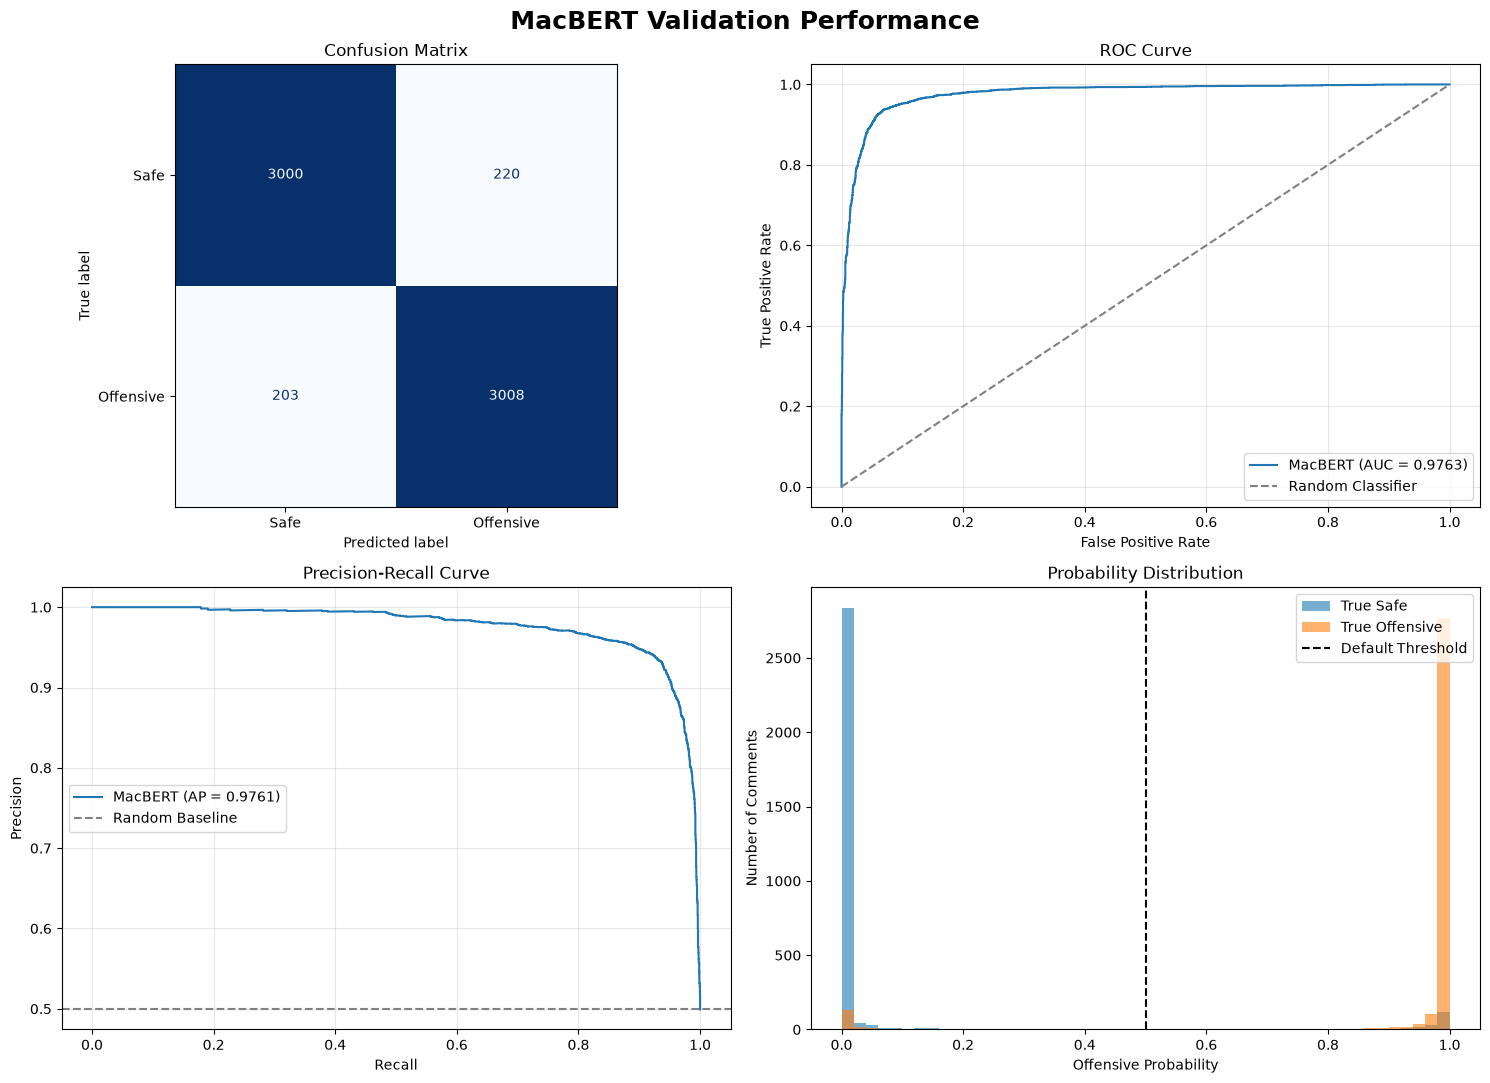

In [ ]:
# ==========================================
# Model Performance Visualization
# ==========================================

fig, axes = plt.subplots(2, 2, figsize=(15, 11))

# 1. Confusion Matrix
cm = confusion_matrix(y_true, y_pred, labels=[0, 1])

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Safe", "Offensive"]
)

disp.plot(
    ax=axes[0, 0],
    cmap="Blues",
    values_format="d",
    colorbar=False
)

axes[0, 0].set_title("Confusion Matrix")


# 2. ROC Curve
fpr, tpr, roc_thresholds = roc_curve(y_true, y_prob)
roc_auc = auc(fpr, tpr)

axes[0, 1].plot(fpr, tpr, label=f"MacBERT (AUC = {roc_auc:.4f})")
axes[0, 1].plot([0, 1], [0, 1], linestyle="--", color="gray", label="Random Classifier")
axes[0, 1].set_xlabel("False Positive Rate")
axes[0, 1].set_ylabel("True Positive Rate")
axes[0, 1].set_title("ROC Curve")
axes[0, 1].legend()
axes[0, 1].grid(alpha=0.3)



# 3. Precision-Recall Curve
precision, recall, pr_thresholds = precision_recall_curve(
    y_true, y_prob
)

ap = average_precision_score(y_true, y_prob)

axes[1, 0].plot(
    recall, precision,
    label=f"MacBERT (AP = {ap:.4f})"
)

axes[1, 0].axhline(
    y=y_true.mean(),
    linestyle="--",
    color="gray",
    label="Random Baseline"
)

axes[1, 0].set_xlabel("Recall")
axes[1, 0].set_ylabel("Precision")
axes[1, 0].set_title("Precision-Recall Curve")
axes[1, 0].legend()
axes[1, 0].grid(alpha=0.3)



# 4. Probability Distribution
axes[1, 1].hist(
    y_prob[y_true == 0],
    bins=50,
    range=(0, 1),
    alpha=0.6,
    label="True Safe"
)

axes[1, 1].hist(
    y_prob[y_true == 1],
    bins=50,
    range=(0, 1),
    alpha=0.6,
    label="True Offensive"
)

axes[1, 1].axvline(
    x=0.5,
    color="black",
    linestyle="--",
    label="Default Threshold"
)

axes[1, 1].set_xlabel("Offensive Probability")
axes[1, 1].set_ylabel("Number of Comments")
axes[1, 1].set_title("Probability Distribution")
axes[1, 1].legend()


# 5. Overall Figure
fig.suptitle(
    "MacBERT Validation Performance",
    fontsize=18,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

Total Errors: 423


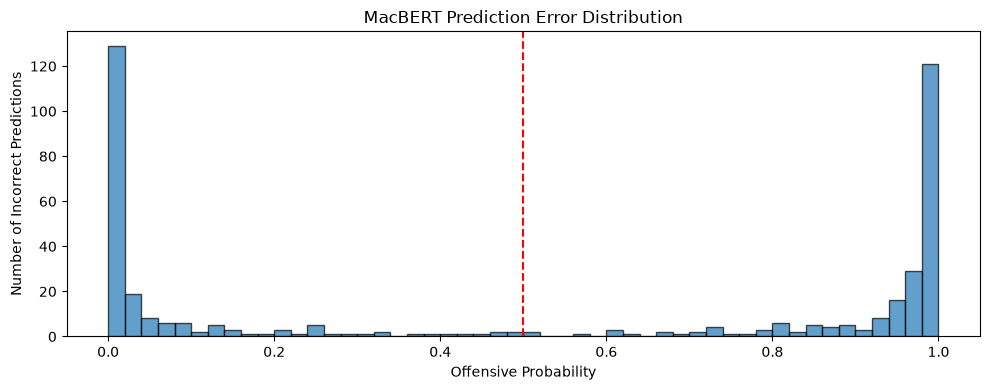

In [ ]:
# ==========================================
# Prediction Error Distribution
# ==========================================

error_mask = y_true != y_pred
error_probabilities = y_prob[error_mask]
print("Total Errors:", error_mask.sum())

plt.figure(figsize=(10, 4))
plt.hist(
    error_probabilities,
    bins=50,
    range=(0, 1),
    edgecolor="black",
    alpha=0.7
)

plt.axvline(
    x=0.5,
    color="red",
    linestyle="--"
)

plt.xlabel("Offensive Probability")
plt.ylabel("Number of Incorrect Predictions")
plt.title("MacBERT Prediction Error Distribution")

plt.tight_layout()
plt.show()